In [2]:
import sys
print("Python version:")
print(sys.version)
print("\nPython executable:")
print(sys.executable)

Python version:
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]

Python executable:
c:\Users\linah\OneDrive\Documenti\GitHub\intelligent_lip_detection\.venv\Scripts\python.exe


### 1. Install the download library

In [3]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.


### 2. Download and extract GRID Speaker 1

In [4]:
from pathlib import Path
import requests
import zipfile

# Locate the project directory
project_root = Path.cwd().parent
# Create the dataset folders
dataset_folder = (
    project_root
    / "data"
    / "datasets"
    / "GRID"
    / "speaker_01"
)

zip_folder = dataset_folder / "downloads"
video_folder = dataset_folder / "raw_videos"
zip_folder.mkdir(parents=True, exist_ok=True)
video_folder.mkdir(parents=True, exist_ok=True)

# Official GRID Speaker 1 download link
url = "https://spandh.dcs.shef.ac.uk/gridcorpus/s1/video/s1.mpg_vcd.zip"
zip_path = zip_folder / "s1.mpg_vcd.zip"

# Download the archive if it does not already exist
if not zip_path.exists():
    print("Starting GRID dataset download...")
    response = requests.get(url, stream=True, timeout=60)
    response.raise_for_status()
    total_size = int(response.headers.get("content-length", 0))
    downloaded = 0

    with open(zip_path, "wb") as file:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                file.write(chunk)
                downloaded += len(chunk)
                if total_size:
                    percentage = downloaded / total_size * 100
                    print(f"\rDownloaded: {percentage:.1f}%",end="")
    print("\nDownload completed!")
else:
    print("The ZIP file already exists. Skipping download.")

# Extract the archive
print("Extracting videos...")

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(video_folder)

print("Extraction completed!")
print("\nDataset location:")
print(video_folder)

Starting GRID dataset download...
Downloaded: 100.0%
Download completed!
Extracting videos...
Extraction completed!

Dataset location:
c:\Users\linah\OneDrive\Documenti\GitHub\intelligent_lip_detection\data\datasets\GRID\speaker_01\raw_videos


### 3. Verify that the videos were extracted

In [6]:
from pathlib import Path

video_folder = (
    project_root
    / "data"
    / "datasets"
    / "GRID"
    / "speaker_01"
    / "raw_videos")

video_extensions = [
    "*.mpg",
    "*.mpeg",
    "*.mp4",
    "*.avi"]

video_files = []
for extension in video_extensions:
    video_files.extend(video_folder.rglob(extension))

print("Total video files found:", len(video_files))
print("\nFirst 10 video files:")
for video in video_files[:10]:
    print(video.name)

Total video files found: 1000

First 10 video files:
bbaf2n.mpg
bbaf3s.mpg
bbaf4p.mpg
bbaf5a.mpg
bbal6n.mpg
bbal7s.mpg
bbal8p.mpg
bbal9a.mpg
bbas1s.mpg
bbas2p.mpg


### 4. Display a video frame

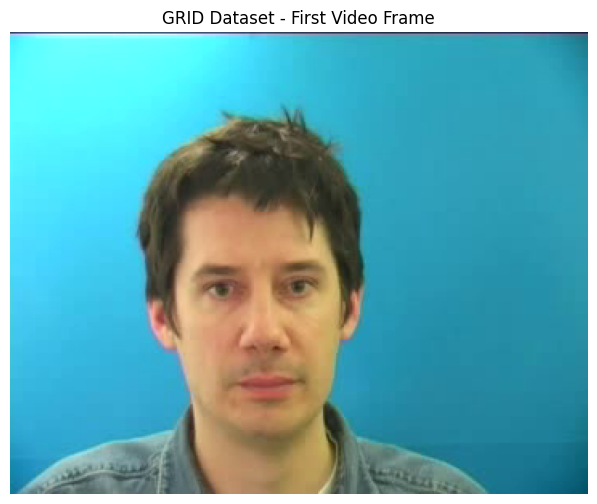

Video: c:\Users\linah\OneDrive\Documenti\GitHub\intelligent_lip_detection\data\datasets\GRID\speaker_01\raw_videos\s1\bbaf2n.mpg
Width: 360
Height: 288
FPS: 25.0
Total frames: 75


In [7]:
import cv2
import matplotlib.pyplot as plt

if len(video_files) > 0:
    video_path = str(video_files[0])
    cap = cv2.VideoCapture(video_path)
    success, frame = cap.read()
    if success:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(10, 6))
        plt.imshow(frame_rgb)
        plt.title("GRID Dataset - First Video Frame")
        plt.axis("off")
        plt.show()

        print("Video:", video_path)
        print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
        print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
        print("FPS:", cap.get(cv2.CAP_PROP_FPS))
        print(
            "Total frames:",
            int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        )
    else:
        print("OpenCV could not read the video.")
    cap.release()
else:
    print("No videos found. Check the dataset folder.")